# Case Study - Spam Detection

The main aim of this project is to demonstrate the basics of Natural Language Processing (NLP).

**Major Steps Involved:**
1. **Text Data Visualisation**
2. **Text Data Preprocessing**
3. **Text Data To Numerical Vector Conversion using Bag of Words**

We will follow the steps mentioned below:

1. Data Loading
2. Exploratory Data Analysis
3. Data Preparation
    - Train Test Split
    - Data Preprocessing (special characters, stop words, lower case, stemming, etc)
    - Converting text to numerical vector using Bag of Words
    - Preprocessing Test Data
4. Training on Train Data
5. Predictions on Test Data
6. Model Evaluation

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

### Read the Data

In [2]:
df = pd.read_csv('C:\Ruquayya Banu\Data Science\Datasets\email_data.csv')

df.head()

,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


In [3]:
df.shape

(5171, 4)

### Exploratory Data Analysis

In [4]:
df['label'].value_counts() # count of harmless and spam count 

label
ham     3672
spam    1499
Name: count, dtype: int64

In [5]:
df['label'].value_counts(normalize=True) #percentage wise checking the count of harmless ans spam email
# 71% are harmless mail
# 28% are spam mail

label
ham     0.710114
spam    0.289886
Name: proportion, dtype: float64

<Axes: xlabel='label', ylabel='count'>

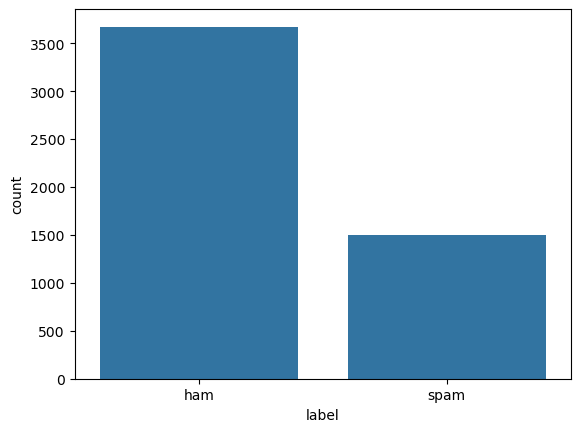

In [6]:
sns.countplot(x='label', data=df)

### Data Preparation - Split the data into train and test set

In [7]:
df.columns # check the column names 

Index(['Unnamed: 0', 'label', 'text', 'label_num'], dtype='object')

In [8]:
# unnamed label we need to drop as it contain id which is not useful
df = df.drop('Unnamed: 0', axis=1)

df.head()

,label,text,label_num
0,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,spam,"Subject: photoshop , windows , office . cheap ...",1
4,ham,Subject: re : indian springs\nthis deal is to ...,0


In [9]:
y = df['label']  # target feature
X = df[['text']]  # input feature

In [10]:
# Splitting into train and test

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [11]:
X_train.head()

,text
5132,Subject: april activity surveys\nwe are starti...
2067,Subject: message subject\nhey i ' am julie ^ _...
4716,Subject: txu fuels / sds nomination for may 20...
4710,Subject: re : richardson volumes nov 99 and de...
2268,Subject: a new era of online medical care .\na...


In [12]:
X_train.shape

(4136, 1)

### Data Prepration - Text Preprocessing

In [3]:
import nltk # library for text preprocessing - natural language tool kit
nltk.download() # always update this - as it get frequently update library

showing info https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/index.xml


True

In [13]:
import re  # regex or regular expression
from nltk.tokenize import word_tokenize # process of breaking down into individulas (words)tokens
# in corpus all words documnet is stored
from nltk.corpus import stopwords # stopwords are is,and,of,the,in,at,for,etc....
from nltk.stem.porter import PorterStemmer # PorterStemmer remove the english suffix from the word(ex: -ing,-ed,-s) - understanding the proper word without any suffix
# Stemmer is steming - chopping words like "writing" to "write" , "informed" to "inform","plays" to "play" etc....
from nltk.stem import WordNetLemmatizer  # it should convert it into proper tense(past,present,future) format
# WordNetLemmatizer:-
# "i ate an apple" and "i'm going to eat an apple" => ate and eat it will convert it into proper understandable word "eat"
# "bad" and "worst" => it will convert it into "bad" word
# reduceing the word to the base dictionary

In [14]:
## initialise the inbuilt Stemmer
stemmer = PorterStemmer()

In [15]:
## We can also use Lemmatizer instead of Stemmer
lemmatizer = WordNetLemmatizer()

In [41]:
# if data is in like other language such as marathi,hindi,spanish,japanese,etc.. convert it into english and do text pre processing
# basically text preprocessing language understandable model you need to give the text data

def preprocess(raw_text, flag):
    
    # Removing special characters and digits
    # re.sub is for replace
    # capital and small a-z are only allowed - other than this replace it with space
    sentence = re.sub("[^a-zA-Z]", " ", raw_text) # regural expression - substitute
    
    # change sentence to lower case
    sentence = sentence.lower()

    # tokenize into words
    tokens = sentence.split() # convert to list of words(e.g "like to play" will become ["like","to","play"])
    
    # remove stop words                
    clean_tokens = [t for t in tokens if not t in stopwords.words("english")]
    
    # Stemming/Lemmatization - deal with tenses (e.g - "doesn't" will become "do not" or "does not")
    if(flag == 'stem'):
        clean_tokens = [stemmer.stem(word) for word in clean_tokens]
    else:
        clean_tokens = [lemmatizer.lemmatize(word) for word in clean_tokens]
    # with the help of join- again putting as statement and also checking the length of it
    return pd.Series([" ".join(clean_tokens), len(clean_tokens)])

In [53]:
# example to understand the above preprocess function

# see the difference in below two statement
text = "He doesn't like english much"
text1 = "He doesnt like english much" 

# removeing "doesnt" word do not make change the meaning of statememt but it check the entire corpus and it will take it in count vector.
# text = re.sub(r"doesn\'t","does not",text) # punction mark represent like this for all words manually- doesnt,cant,etc....
text = re.sub("[^a-zA-Z]", " ",text)
print(text)
text= text.split()
print(text)
clean_tokens = [t for t in text if not t in stopwords.words("english")]
print(clean_tokens)
clean_tokens = [stemmer.stem(word) for word in clean_tokens]
clean_tokens = [lemmatizer.lemmatize(word) for word in clean_tokens]
" ".join(clean_tokens)

# watching the directory of stop words
s = stopwords.words("english")
stop_words = set(s)
print(stop_words)

He doesn t like english much
['He', 'doesn', 't', 'like', 'english', 'much']
['He', 'like', 'english', 'much']
{"should've", 'above', 'now', 'again', 'which', 'whom', "haven't", 'won', 'there', "i've", 'couldn', "he'd", 'out', "i'm", "weren't", 'his', "you're", 'up', "couldn't", 'how', 'for', 'of', "she'd", 'has', 'should', 'down', 'does', 'myself', 'once', "we've", "it'll", 'further', 'm', 'from', 'few', 'own', "you'll", 'am', 'ain', 'hers', 'him', 'the', 'hasn', 'ourselves', 'through', 'all', 'any', 'was', 'itself', 'in', 'each', "they're", 'doing', 'ours', 'haven', 'this', 'y', "won't", 'between', 'yourselves', 'our', 'to', 'nor', 'same', 'some', "they'd", 'other', "they've", 'theirs', 'don', 'too', 'be', 'more', 'who', 'on', 'wasn', "that'll", 'd', "we'll", 'herself', 'been', "mightn't", 'yours', "i'll", 'did', 'i', 'her', 'we', 'under', 'most', 've', 'against', 'that', "they'll", 'when', 'so', "we're", 'an', 'why', 'is', 'no', "shan't", 'do', 'them', 'those', "it's", 'as', 'ma', "

In [184]:
# after complete the full code. we are giving the one sentence to check 

str_pred="Subject: Christmas and new year wishes. \n\n I hope you are doing good"

In [34]:
# %%timeit

# # Convert to series
X_train['text'].apply(lambda x: preprocess(x, 'stem'))

# # 2min 35 sec approx run time

,0,1
5132,subject april activ survey start collect data ...,88
2067,subject messag subject hey juli turn high scho...,44
4716,subject txu fuel sd nomin may attach may nomin...,34
4710,subject richardson volum nov dec meter nick su...,105
2268,subject new era onlin medic care new era onlin...,36
...,...,...
4426,subject ena sale hpl last legal review contrac...,476
466,subject tenaska iv bob understand sandi handl ...,208
3092,subject broom bristl flew differenti onomatopo...,128
3772,subject calpin daili ga nomin weekend ricki ar...,21


In [18]:
# !pip install tqdm

In [59]:
from tqdm import tqdm, tqdm_notebook
# tqdm helps to process functions bit fast when we have huge dataset

In [57]:
# Register `pandas.progress_apply` and `pandas.Series.map_apply` with `tqdm`
# this is for bossting it (e.g:- like when inter is slow we use booster technique to fast the process)
tqdm.pandas()

In [58]:
# Now you can use `progress_apply` instead of `apply`
# and `progress_map` instead of `map`

temp_df = X_train['text'].progress_apply(lambda x: preprocess(x, 'stem'))

temp_df.head()
# 4136 documnents we have

100%|██████████| 4136/4136 [07:00<00:00,  9.83it/s]


,0,1
5132,subject april activ survey start collect data ...,88
2067,subject messag subject hey juli turn high scho...,44
4716,subject txu fuel sd nomin may attach may nomin...,34
4710,subject richardson volum nov dec meter nick su...,105
2268,subject new era onlin medic care new era onlin...,36


In [60]:
# 5132 - emails we have with same set of subject
# column 0	- tells us that subject
# column 1 -  tells the 88 words we have in that documnet

In [65]:
# renaming the column names
# text_length_stem column gives total number of vocabulary in each documnet
temp_df.columns = ['clean_text_stem', 'text_length_stem']

temp_df.head()

,clean_text_stem,text_length_stem
5132,subject april activ survey start collect data ...,88
2067,subject messag subject hey juli turn high scho...,44
4716,subject txu fuel sd nomin may attach may nomin...,34
4710,subject richardson volum nov dec meter nick su...,105
2268,subject new era onlin medic care new era onlin...,36


In [66]:
# concatinating the training data with temporary df
# this will show the comparison 
# test data before and after - of preprocessing
X_train = pd.concat([X_train, temp_df], axis=1)

X_train.head()

,text,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem
5132,Subject: april activity surveys\nwe are starti...,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88
2067,Subject: message subject\nhey i ' am julie ^ _...,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44
4716,Subject: txu fuels / sds nomination for may 20...,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34
4710,Subject: re : richardson volumes nov 99 and de...,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105
2268,Subject: a new era of online medical care .\na...,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36


In [68]:
# lemma is for lemmatization
temp_df = X_train['text'].progress_apply(lambda x: preprocess(x, 'lemma')) # stem or lemma anything we can pass

temp_df.head()

100%|██████████| 4136/4136 [06:47<00:00, 10.15it/s]


,0,1
5132,subject april activity survey starting collect...,88
2067,subject message subject hey julie turned high ...,44
4716,subject txu fuel sd nomination may attached ma...,34
4710,subject richardson volume nov dec meter nick s...,105
2268,subject new era online medical care new era on...,36


In [69]:

temp_df.columns = ['clean_text_lemma', 'text_length_lemma']

temp_df.head()

,clean_text_lemma,text_length_lemma
5132,subject april activity survey starting collect...,88
2067,subject message subject hey julie turned high ...,44
4716,subject txu fuel sd nomination may attached ma...,34
4710,subject richardson volume nov dec meter nick s...,105
2268,subject new era online medical care new era on...,36


In [70]:
X_train = pd.concat([X_train, temp_df], axis=1)

X_train.head()

,text,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_lemma,text_length_lemma
5132,Subject: april activity surveys\nwe are starti...,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activity survey starting collect...,88
2067,Subject: message subject\nhey i ' am julie ^ _...,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject message subject hey julie turned high ...,44
4716,Subject: txu fuels / sds nomination for may 20...,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomination may attached ma...,34
4710,Subject: re : richardson volumes nov 99 and de...,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volume nov dec meter nick s...,105
2268,Subject: a new era of online medical care .\na...,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era online medical care new era on...,36


In [71]:
X_train.head()

,text,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_lemma,text_length_lemma
5132,Subject: april activity surveys\nwe are starti...,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activity survey starting collect...,88
2067,Subject: message subject\nhey i ' am julie ^ _...,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject message subject hey julie turned high ...,44
4716,Subject: txu fuels / sds nomination for may 20...,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomination may attached ma...,34
4710,Subject: re : richardson volumes nov 99 and de...,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volume nov dec meter nick s...,105
2268,Subject: a new era of online medical care .\na...,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era online medical care new era on...,36


## Creating the WordCloud

In [79]:
# WordCloud finds the words, which are very popular in spam email
# WordCloud finds the words, which are very popular for harmless email

In [84]:
pip install wordcloud

Defaulting to user installation because normal site-packages is not writeableNote: you may need to restart the kernel to use updated packages.



In [81]:
from wordcloud import WordCloud

In [82]:
y_train

5132     ham
2067    spam
4716     ham
4710     ham
2268    spam
        ... 
4426     ham
466      ham
3092    spam
3772     ham
860      ham
Name: label, Length: 4136, dtype: object

In [89]:
# filter the data only gor spam type email
# e.g druuug, onliiiiine, cheaaaap   
# from text column "onliiiiine" to "onliiiiin" to "onliiiiine" => stem remove suffix from english

spam_df = X_train.loc[y_train=='spam', :]

spam_df.head()

,text,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_lemma,text_length_lemma
2067,Subject: message subject\nhey i ' am julie ^ _...,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject message subject hey julie turned high ...,44
2268,Subject: a new era of online medical care .\na...,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era online medical care new era on...,36
4998,Subject: sparkasse security issue\nsehr geehrt...,subject sparkass secur issu sehr geehrt kundin...,132,subject sparkass secur issu sehr geehrt kundin...,132,subject sparkass secur issu sehr geehrt kundin...,132,subject sparkasse security issue sehr geehrte ...,132
366,Subject: druuugs onliiiiine very cheaaaap\nhel...,subject druuug onliiiiin cheaaaap hello calvin...,50,subject druuug onliiiiin cheaaaap hello calvin...,50,subject druuug onliiiiin cheaaaap hello calvin...,50,subject druuugs onliiiiine cheaaaap hello calv...,50
2683,Subject: survivor junction\na genuine college ...,subject survivor junction genuin colleg degre ...,139,subject survivor junction genuin colleg degre ...,139,subject survivor junction genuin colleg degre ...,139,subject survivor junction genuine college degr...,139


In [93]:
# extracted first row of spam email
words = ' '.join(spam_df['clean_text_lemma'])

print(words[:100])

subject message subject hey julie turned high school senior houston tx waiting long time day finally


In [100]:
spam_df = X_train.loc[y_train=='spam', :]

words = ' '.join(spam_df['clean_text_lemma'])

# spliting all words
# enitre courpus of spam email
# we get the clean word
cleaned_word = " ".join([word for word in words.split()  
                        if 'subject' not in word])
cleaned_word

'message hey julie turned high school senior houston tx waiting long time day finally got wish simply trying show meet new cyber friend know lead worry usually online free go thru age verification youngers snooping around hehe http oioaz stuntscholar com ju new era online medical care new era online medical care nudity objectionable naked truth man think mouthing hard word understands hard thing free prejudice hate everyone equally great spirit always encountered violent opposition mediocre mind sparkasse security issue sehr geehrte kundin sehr geehrter kunde im zusammenhang mit der komplizierten situation die unserem land mit online banking zustande gekommen ist haben wir die verordnung bekommen alle online konten von unserer bank zu berprfen diese manahme wurde wegen der tageskonten getroffen die von den missettern fr geldwsche der gestohlenen mittel benutzt werden wir bitten unsere kunden instndig die form der kontobesttigung auf unserer offiziellen seite auszufllen die konten die b

In [105]:
# for plotting the graph
spam_wordcloud = WordCloud(stopwords=stopwords.words("english"),
                      background_color='black',
                      width=1600,
                      height=800
                     ).generate(cleaned_word)
spam_wordcloud

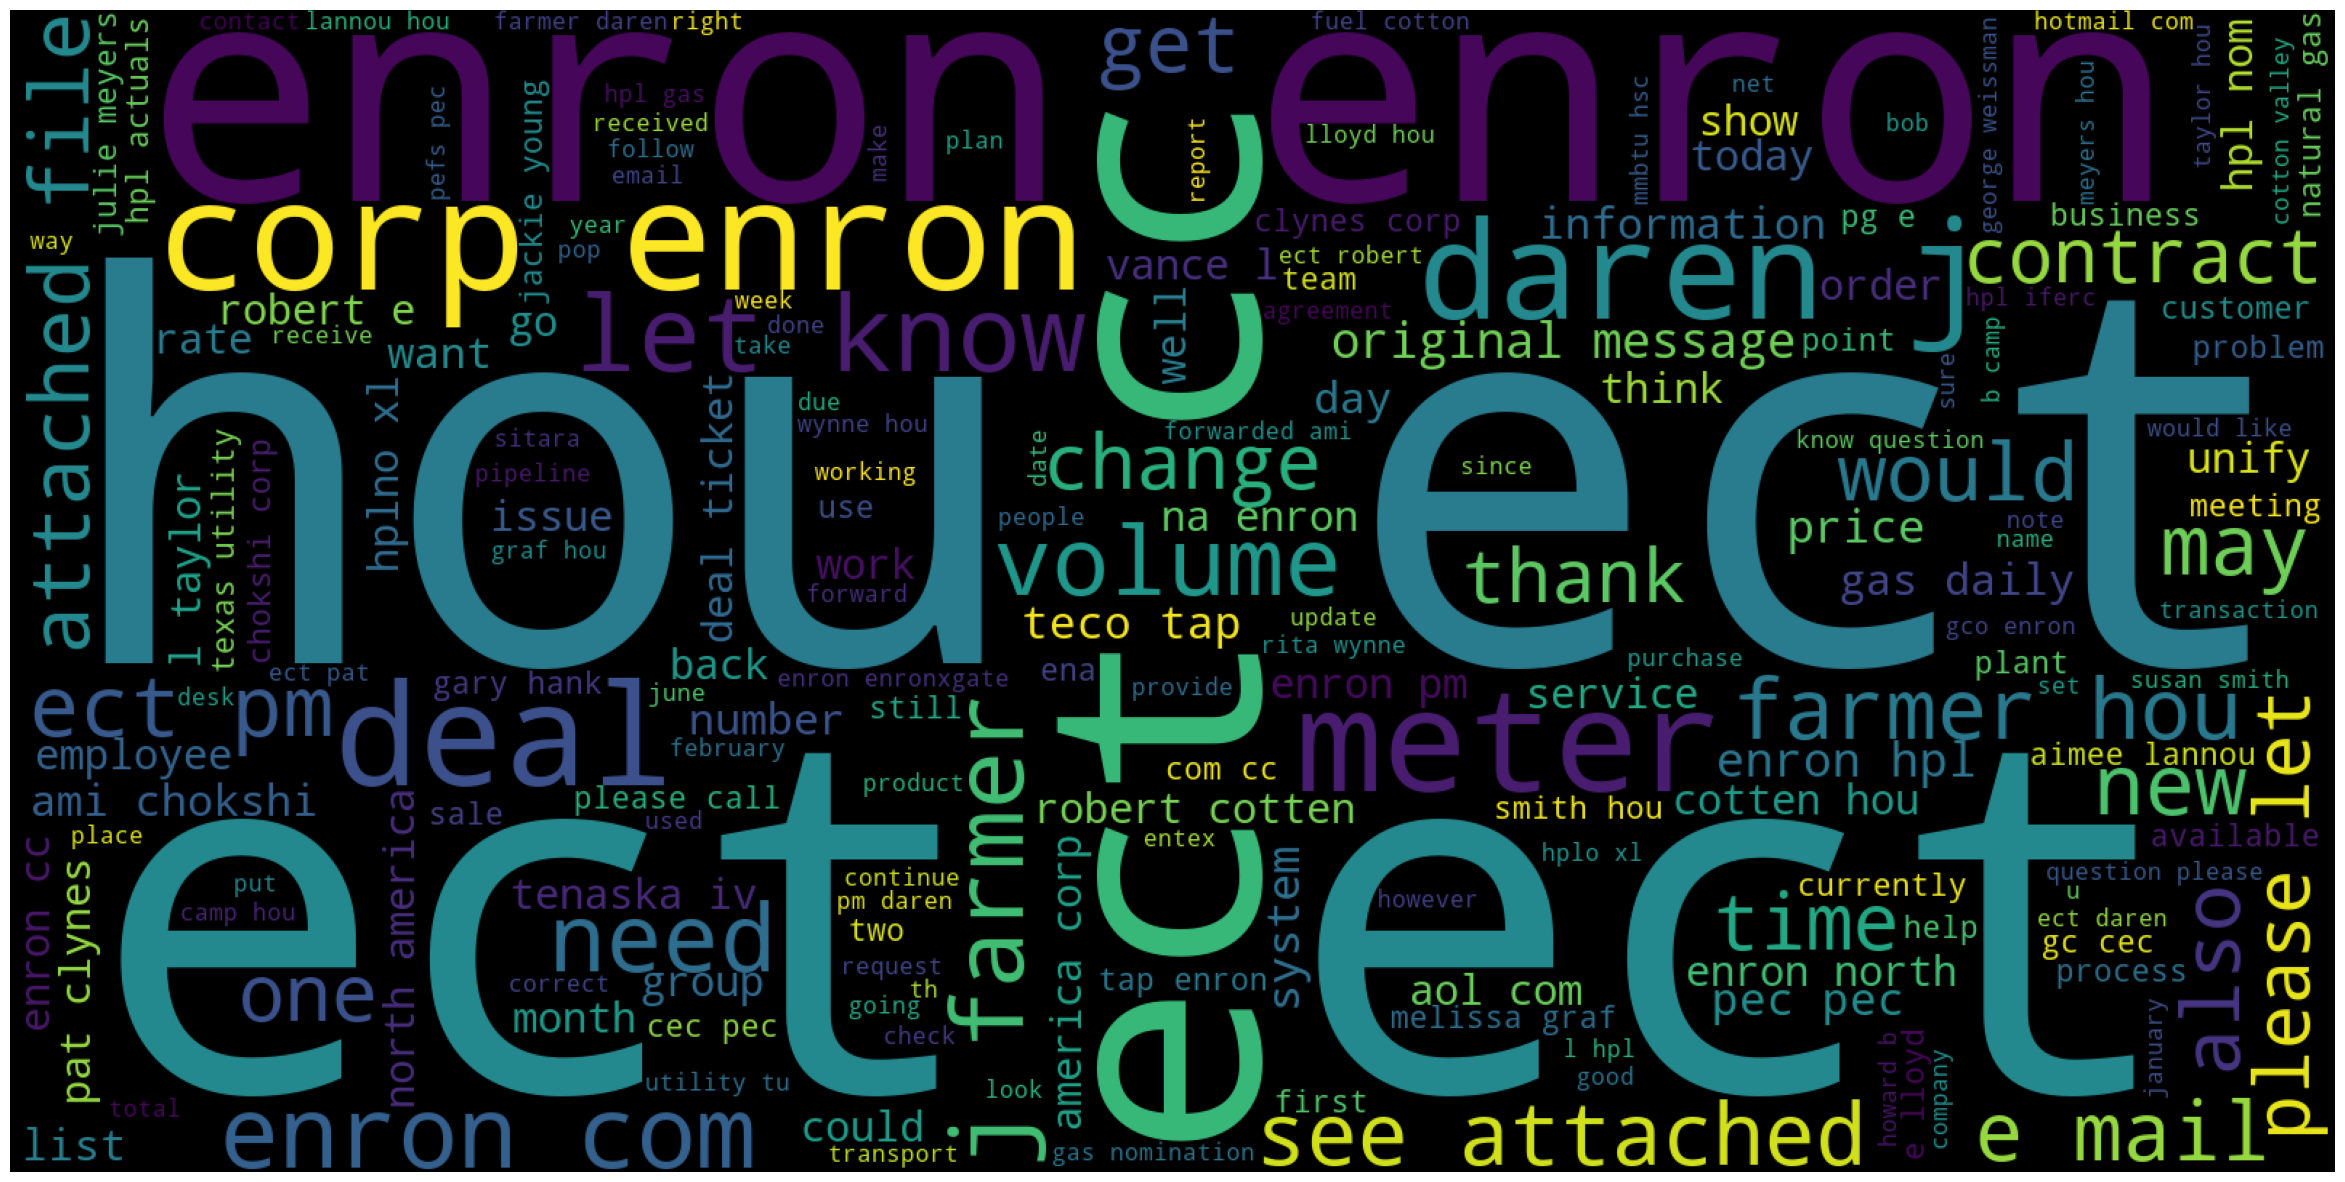

In [106]:
plt.figure(1,figsize=(30,20))
plt.imshow(spam_wordcloud)
plt.axis('off')
plt.show()
# based on word size in image - define it is accuring most frequently

In [107]:
# filter all the  harmless email
ham_df = X_train.loc[y_train=='ham', :]

# get the clean text using lema
words = ' '.join(ham_df['clean_text_lemma'])

# pick all the words where subject word should not be present 
cleaned_word = " ".join([word for word in words.split() 
                        if 'subject' not in word])
cleaned_word

'april activity survey starting collect data april attached survey drive cost activity commercial team please select rcs fill driver quantity requested driver month february please fill attached activity driver survey april number rc end day thursday may th group currently generates standard report capture surveyed data please send report put recipient list beginning next month eliminate need fill survey every month would like u collect information someone within team beginning next month let know please contact lisa cousino x unable complete survey within allotted time thanks shari txu fuel sd nomination may attached may nomination take gas sale purchase contract txu fuel company previously tufco sd please advise question concerning attached thanks cc see attached file sdsnom xl sdsnom xl richardson volume nov dec meter nick sure happened volume cannot tell audit trail connection meter hpl meter midt volume referring mid tex pipeline meter pathed point point nom deal reference think c

In [109]:
# for plotting a graph to get a proper visulaization 
ham_wordcloud = WordCloud(stopwords=stopwords.words("english"),
                      background_color='black',
                      width=1600,
                      height=800
                     ).generate(cleaned_word)

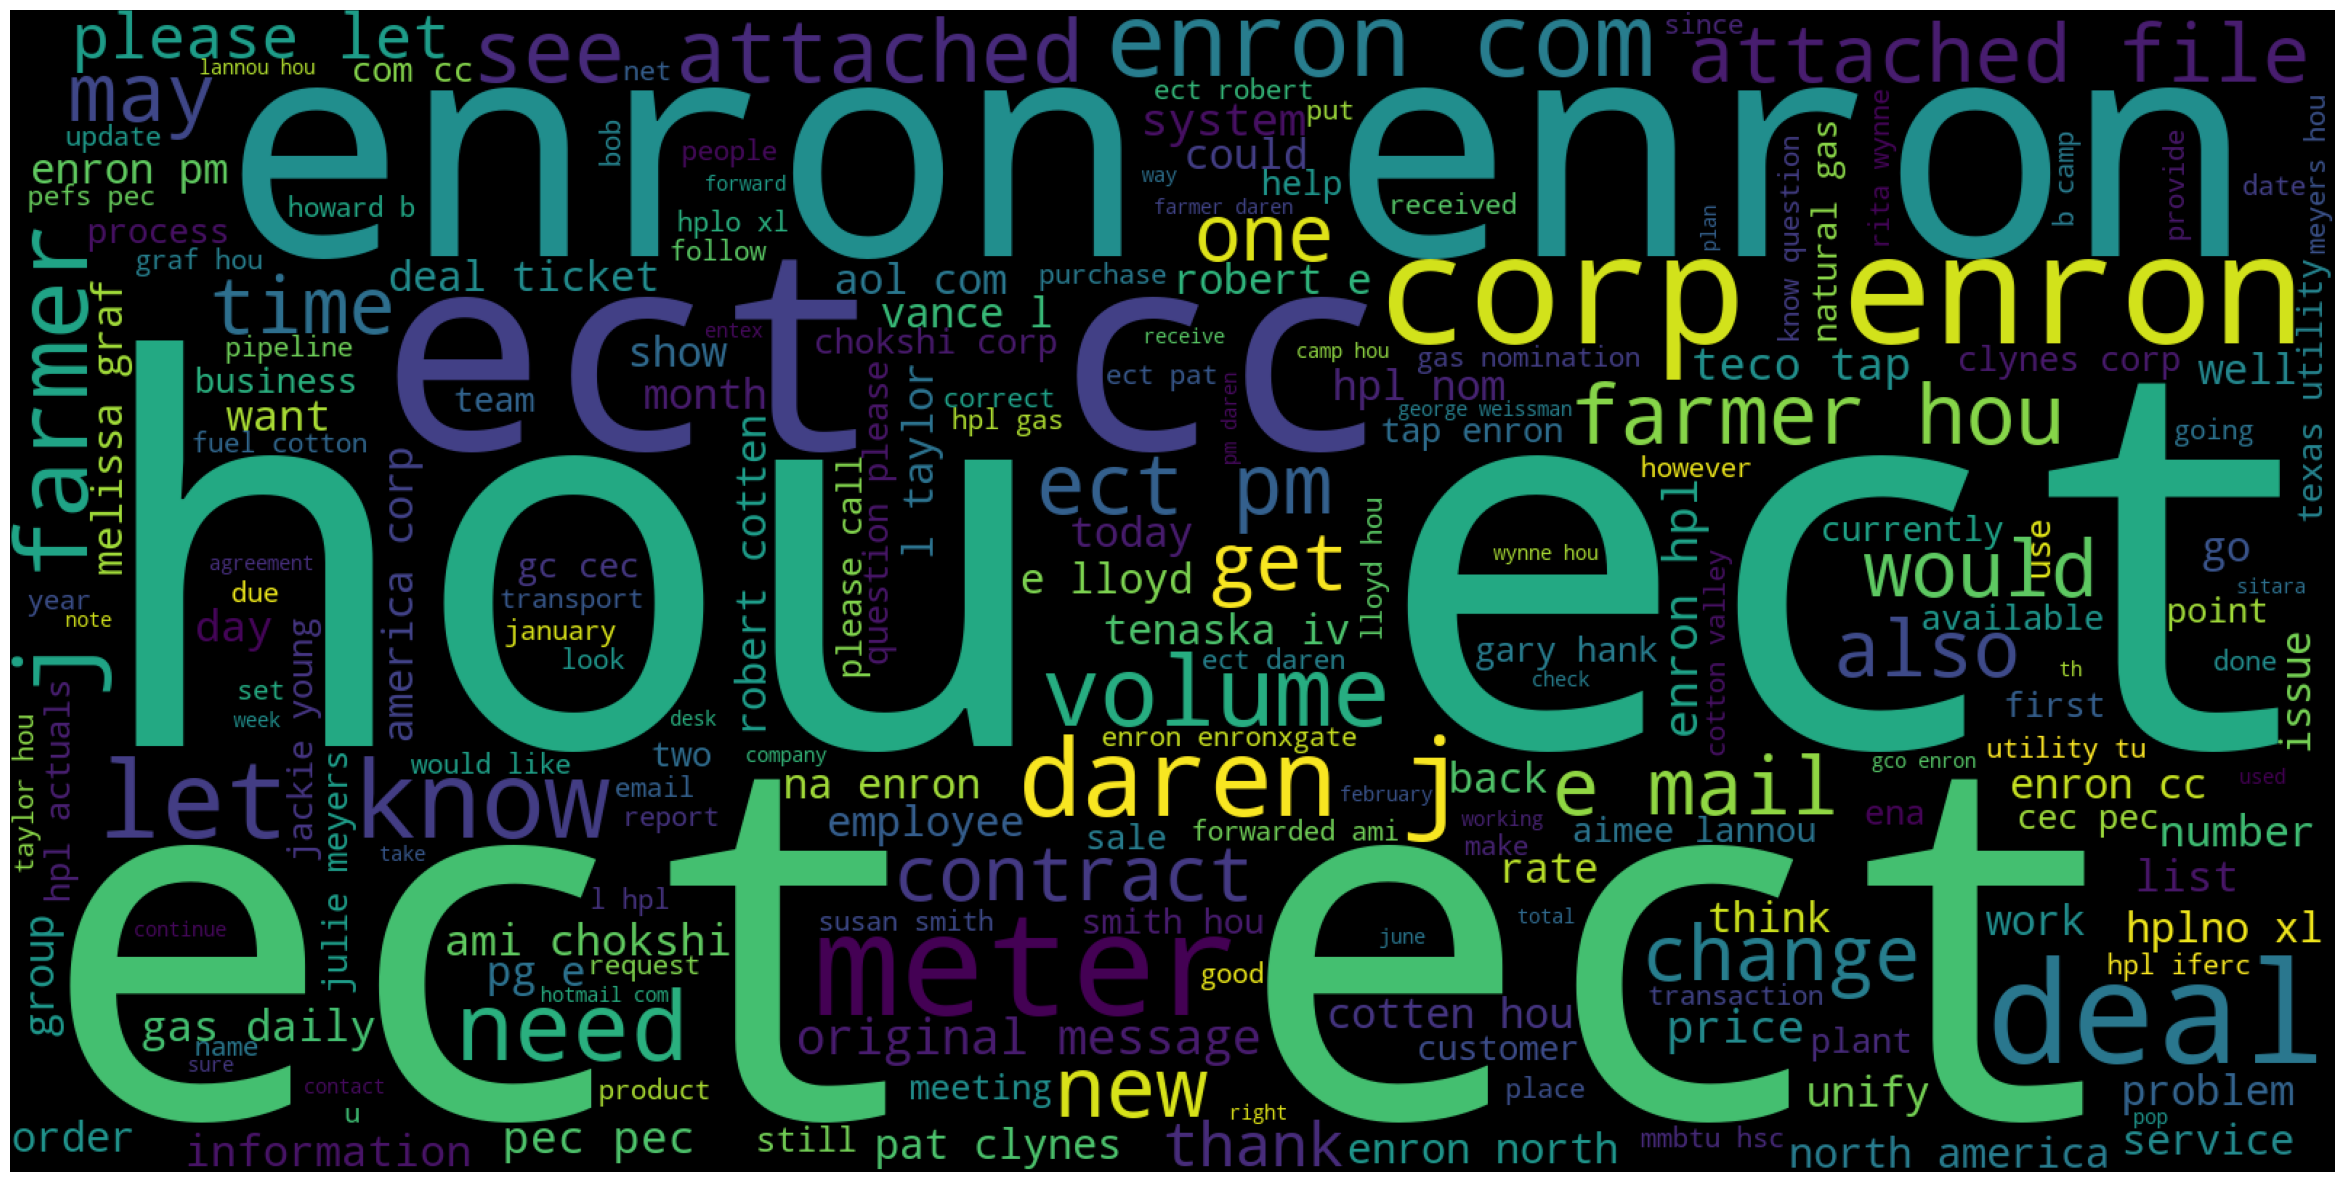

In [110]:
plt.figure(1,figsize=(30,20))
plt.imshow(ham_wordcloud)
plt.axis('off')
plt.show()

## Converting Text to Numerical vectors - Bag Of Words(BOW) Representation

**Step 1** - Learn the vocabulary from the train data  
**Step 2** - Transform the `train['emails']` to `X_train` (i.e. Document Term Matrix(DTM))  
**Step 3** - Transform the `test['emails']` to `X_test` (i.e. DTM)

In [113]:
# Note:- before BOW start you need to do text preprocessing on train and test data

In [114]:
X_train.head()

,text,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_stem,text_length_stem,clean_text_lemma,text_length_lemma
5132,Subject: april activity surveys\nwe are starti...,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activ survey start collect data ...,88,subject april activity survey starting collect...,88
2067,Subject: message subject\nhey i ' am julie ^ _...,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject messag subject hey juli turn high scho...,44,subject message subject hey julie turned high ...,44
4716,Subject: txu fuels / sds nomination for may 20...,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomin may attach may nomin...,34,subject txu fuel sd nomination may attached ma...,34
4710,Subject: re : richardson volumes nov 99 and de...,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volum nov dec meter nick su...,105,subject richardson volume nov dec meter nick s...,105
2268,Subject: a new era of online medical care .\na...,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era onlin medic care new era onlin...,36,subject new era online medical care new era on...,36


In [117]:
# for BOW import CountVectorizer
from sklearn.feature_extraction.text import CountVectorizer

vocab = CountVectorizer()

# choose the column wisely - otherwise you will endup curse of dimensionality
# we choose lemitaization beacuse it choose logical conversation - even after remove of suffix
# for training data use fit transformation
X_train_bow = vocab.fit_transform(X_train['clean_text_lemma'])


In [123]:
X_train_bow # sparse matrix means more zero's will be there
# 252681 number of features got create - curse of dimensionality
# 38719 unique words are there 
# 4136 rows/documnets

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 252681 stored elements and shape (4136, 38719)>

In [124]:
print("Total unique words:", len(vocab.vocabulary_))

print("Type of train features:", type(X_train_bow))

print("Shape of input data:", X_train_bow.shape)

Total unique words: 38719
Type of train features: <class 'scipy.sparse._csr.csr_matrix'>
Shape of input data: (4136, 38719)


In [126]:
print(X_train_bow.toarray()) #many zeros(sparse)

[[0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 0 0 0]]


In [128]:
# size of matrix in bytes before converting it into array
from sys import getsizeof

print(type(X_train_bow))
print(getsizeof(X_train_bow), "Bytes")

<class 'scipy.sparse._csr.csr_matrix'>
48 Bytes


In [131]:
# size of matrix in bytes after converting it into array
from sys import getsizeof

print(type(X_train_bow.toarray()))
print(getsizeof(X_train_bow.toarray()), "Bytes")
# lot of space is getting capture in memory

<class 'numpy.ndarray'>
1281134400 Bytes


## Preprocessing the Test Data

In [133]:
X_test.head()

,text
1566,"Subject: hpl nom for march 30 , 2001\n( see at..."
1988,Subject: online pharxmacy 80 % off all meds\nd...
1235,Subject: re : nom / actual volume for april 17...
2868,Subject: re : meter 8740 dec 99\nrobert and i ...
4903,Subject: re : coastal oil & gas corporation\nm...


In [135]:
# performing lemetization on test data - if we do lema in train then we need to do lema on test data also
temp_df = X_test['text'].progress_apply(lambda x: preprocess(x, 'lemma'))

temp_df.head()

100%|██████████| 1035/1035 [00:17<00:00, 58.22it/s]


,0,1
1566,subject hpl nom march see attached file hplno ...,11
1988,subject online pharxmacy med disscount phafrma...,2590
1235,subject nom actual volume april th agree eilee...,44
2868,subject meter dec robert put head together dec...,332
4903,subject coastal oil gas corporation melissa de...,1241


In [136]:
# change the column name 
temp_df.columns = ['clean_text_lemma', 'text_length_lemma']

temp_df.head()

,clean_text_lemma,text_length_lemma
1566,subject hpl nom march see attached file hplno ...,11
1988,subject online pharxmacy med disscount phafrma...,2590
1235,subject nom actual volume april th agree eilee...,44
2868,subject meter dec robert put head together dec...,332
4903,subject coastal oil gas corporation melissa de...,1241


In [139]:
# merge will give you orginal text,clean text and count of unique words
X_test = pd.concat([X_test, temp_df], axis=1)

X_test.head()

,text,clean_text_lemma,text_length_lemma,clean_text_lemma,text_length_lemma,clean_text_lemma,text_length_lemma
1566,"Subject: hpl nom for march 30 , 2001\n( see at...",subject hpl nom march see attached file hplno ...,11,subject hpl nom march see attached file hplno ...,11,subject hpl nom march see attached file hplno ...,11
1988,Subject: online pharxmacy 80 % off all meds\nd...,subject online pharxmacy med disscount phafrma...,2590,subject online pharxmacy med disscount phafrma...,2590,subject online pharxmacy med disscount phafrma...,2590
1235,Subject: re : nom / actual volume for april 17...,subject nom actual volume april th agree eilee...,44,subject nom actual volume april th agree eilee...,44,subject nom actual volume april th agree eilee...,44
2868,Subject: re : meter 8740 dec 99\nrobert and i ...,subject meter dec robert put head together dec...,332,subject meter dec robert put head together dec...,332,subject meter dec robert put head together dec...,332
4903,Subject: re : coastal oil & gas corporation\nm...,subject coastal oil gas corporation melissa de...,1241,subject coastal oil gas corporation melissa de...,1241,subject coastal oil gas corporation melissa de...,1241


In [140]:
# this is test data - so tranform 
X_test_bow = vocab.transform(X_test['clean_text_lemma'])
X_test_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 0 stored elements and shape (3, 38719)>

In [141]:
# now text type of data got clean - text data we need to give it to any model - so it can understand and perform well

## Logistic Regression

In [148]:
# this is labeled data - so we choosed logistic regression 
# in this data we have y target feature 
# logistic regression have regularization - which help to reduce the curse of dimensionality
# l1(lasso) regularization help to reduce the number of features

In [160]:
# model implementation start
from sklearn.linear_model import LogisticRegression
classifier = LogisticRegression()
classifier.fit(X_train_bow, y_train)
# y_train contain spam and harm combination

LogisticRegression()

In [162]:
# predict 
y_test_pred = classifier.predict(X_test_bow)
y_test_pred

array(['spam', 'spam', 'spam'], dtype=object)

In [163]:
y_test

1566     ham
1988    spam
1235     ham
2868     ham
4903     ham
        ... 
1175    spam
4476     ham
4198    spam
2689     ham
2142     ham
Name: label, Length: 1035, dtype: object

In [168]:
print("X_train_bow:", X_train_bow.shape)
print("y_train:", y_train.shape)

print("X_test_bow:", X_test_bow.shape)
print("y_test:", y_test.shape)


X_train_bow: (4136, 38719)
y_train: (4136,)
X_test_bow: (3, 38719)
y_test: (1035,)


In [177]:
# check for accuracy score
from sklearn.metrics import accuracy_score, classification_report
print(accuracy_score(y_test, y_test_pred))
print(classification_report(y_test, y_test_pred))


## Decision Tree

In [178]:
from sklearn.tree import DecisionTreeClassifier
classifier = DecisionTreeClassifier()
classifier.fit(X_train_bow, y_train)

DecisionTreeClassifier()

In [179]:
y_test_pred = classifier.predict(X_test_bow)

In [59]:
from sklearn.metrics import accuracy_score, classification_report

print(accuracy_score(y_test, y_test_pred))

print(classification_report(y_test, y_test_pred))

0.9478260869565217
              precision    recall  f1-score   support

         ham       0.97      0.96      0.96       742
        spam       0.89      0.92      0.91       293

    accuracy                           0.95      1035
   macro avg       0.93      0.94      0.94      1035
weighted avg       0.95      0.95      0.95      1035



## Random Forest

In [180]:
from sklearn.ensemble import RandomForestClassifier
classifier = RandomForestClassifier()
classifier.fit(X_train_bow, y_train)

RandomForestClassifier()

In [181]:
y_test_pred = classifier.predict(X_test_bow)

In [62]:
from sklearn.metrics import accuracy_score, classification_report

print(accuracy_score(y_test, y_test_pred))

print(classification_report(y_test, y_test_pred))

0.9797101449275363
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       742
        spam       0.95      0.98      0.96       293

    accuracy                           0.98      1035
   macro avg       0.97      0.98      0.98      1035
weighted avg       0.98      0.98      0.98      1035



In [221]:
# Note:- logistic regression is best when we compare F1-Score for all ml model
# data is imbalanced in nature but still my model is performing well. 
# we are considering the F1 Score and it is good for both spam and ham
# more number of data - will help to predict more better result

In [203]:
# after complete the full code. we are giving the one sentence to check - how our model will judge the data

In [212]:
# function preprocessing
#str_pred="Subject: Christmas and new year wishes. \n\n I hope you are doing good, we also doing good here. how is mom and dad?"
str_pred="Subject:photoshop the current image"
x_check = pd.DataFrame(data = {"text":str_pred},index=[0])
x_check

,text
0,Subject:photoshop the current image


In [213]:
# now check given output is spam or harmless email
# lemma will give to check -  lemma is for lemmatization
temp_check = x_check['text'].progress_apply(lambda x: preprocess(x, 'lemma')) # stem or lemma anything we can pass
temp_check


100%|██████████| 1/1 [00:00<00:00, 176.28it/s]


,0,1
0,subject photoshop current image,4


In [214]:
# change the column name 
temp_check.columns = ['clean_text_lemma', 'text_length_lemma']
temp_check

,clean_text_lemma,text_length_lemma
0,subject photoshop current image,4


In [215]:
# now check for bag of words
X_check_bow = vocab.transform(temp_check['clean_text_lemma'])
X_check_bow

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 4 stored elements and shape (1, 38719)>

In [220]:
# applying logistic regression
# model implementation 
classifier_L.predict(X_check_bow)

In [218]:
#just fix the 2 to 3 errorin this file -everything will work properly 